# M08-1 | 兩份同名的 XNNPACKQuantizer：executorch 版與 torchao 測試版

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m08_xnnpack_executorch/01_executorch_vs_torchao_copy.ipynb)

PT2E 有兩份同名的 `XNNPACKQuantizer`，程式碼幾乎相同，行為有差：

| 名稱 | import 路徑 | 是什麼 |
|---|---|---|
| **executorch 版** | `executorch.backends.xnnpack.quantizer.xnnpack_quantizer` | ExecuTorch 的 XNNPACK backend 附的 quantizer，和 `XnnpackPartitioner` 在同一個套件；匯出 `.pte` 用這份 |
| **torchao 測試版** | `torchao.testing.pt2e._xnnpack_quantizer` | torchao 為自己的單元測試留的拷貝（在 `testing` 底下、`_` 開頭，import 時會發出 deprecated 警告） |

M01～M07 用的都是 torchao 測試版，結果才不會隨「有沒有裝 executorch」改變；M08 起改用 executorch 版。換之前，先確認兩份差在哪：

- **A.** 同一個 CatPoolNet，兩份各標了哪些 op。
- **B.** executorch 版的量化規格：static（預設）與 dynamic 兩種模式。
- **C.** module 層級的設定 `set_module_name` 對 conv 生不生效（接 M03-7）。

這本 notebook 需要 executorch（`uv sync --group executorch`）。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "executorch==1.5.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m08_xnnpack_executorch")

In [1]:
import torch
import torch.nn as nn

from common.graph_utils import diff_ops, qspec_summary, short
from common.models import CatPoolNet, TinyConvNet, example_inputs
from common.pt2e import ANNOTATION_KEY, convert_pt2e, export_module, get_xnnpack_api, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import annotation_notes, draw, table

quiet()
_ = torch.manual_seed(0)
SOURCES = {"executorch 版": "executorch", "torchao 測試版": "torchao"}

本專案的 `get_xnnpack_api(source)`、`get_xnnpack_quantizer(source, ...)`（`common/pt2e.py`，不是 torchao 的 API）只做一件事：依 `source` 從上面兩個路徑之一 import `XNNPACKQuantizer` 與 `get_symmetric_quantization_config`。印出實際 import 到的模組：

In [2]:
for label, source in SOURCES.items():
    print(f"{label}：{get_xnnpack_api(source)[0].__module__}")

executorch 版：executorch.backends.xnnpack.quantizer.xnnpack_quantizer
torchao 測試版：torchao.testing.pt2e._xnnpack_quantizer


## A. 同一個 CatPoolNet，兩份各標了哪些 op

CatPoolNet 的中段是 `relu`、`relu_1` → `cat` → `max_pool2d` → `conv2d_2`。對同一張 export 圖各呼叫一次 `quantizer.annotate`（只貼標籤、不插 observer，方便直接比較），標籤用 `annotation_notes` 畫在 node 底下（M03-2）：

In [3]:
def labeled(source, model):
    """export → 只呼叫 annotate，回傳貼好標籤的圖。"""
    gm = export_module(model, example_inputs())
    get_xnnpack_quantizer(source, is_per_channel=True)[0].annotate(gm)
    return gm


model = CatPoolNet().eval()
graphs = {label: labeled(source, model) for label, source in SOURCES.items()}
MIDDLE = ["relu", "relu_1", "cat", "max_pool2d"]


def middle_notes(gm):
    notes = annotation_notes(gm, unlabeled=True)
    return {k: v for k, v in notes.items() if k in MIDDLE}

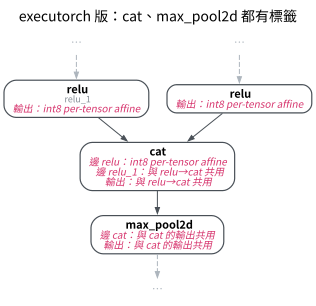

In [4]:
draw(graphs["executorch 版"], focus=MIDDLE, hops=0, notes=middle_notes(graphs["executorch 版"]),
     title="executorch 版：cat、max_pool2d 都有標籤")

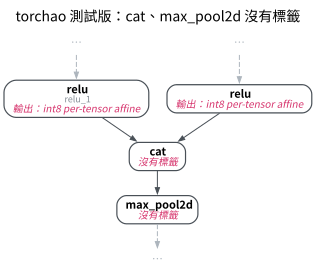

In [5]:
draw(graphs["torchao 測試版"], focus=MIDDLE, hops=0, notes=middle_notes(graphs["torchao 測試版"]),
     title="torchao 測試版：cat、max_pool2d 沒有標籤")

兩張圖的 relu 都有輸出標籤，差在 `cat` 與 `max_pool2d`。用程式比對整張圖，確認只差這兩個：

In [6]:
def has_label(gm):
    return {n.name: ANNOTATION_KEY in n.meta for n in gm.graph.nodes if n.op == "call_function"}


et, ao = (has_label(gm) for gm in graphs.values())
diff = sorted(n for n in et if et[n] != ao[n])
print("兩份標籤不同的 node：", diff)
assert diff == ["cat", "max_pool2d"] and et["cat"] and not ao["cat"]

兩份標籤不同的 node： ['cat', 'max_pool2d']


**`cat`**：兩份的 cat annotator 寫法不同（讀 torchao 0.18、executorch 1.5.0 的原始碼）。

- executorch 版掃過每個 node，直接比對 `node.target == aten.cat.default`。
- torchao 測試版用 `get_source_partitions(gm.graph, [torch.cat])` 找 pattern。這個函式依賴 `node.meta["source_fn_stack"]`，而 torch 2.14 的 `torch.export` 已經不填這個欄位，所以一個都找不到，也不報錯（M01-2）。

**`max_pool2d`**：兩份都沒有 max_pool2d 自己的 annotator。它的標籤來自最後一步 `propagate_annotation`：輸入已經有標籤，就讓 max_pool2d 和輸入共用 qparams（SharedQuantizationSpec，M03-4）。輸入的 `cat` 沒標，它就跟著沒標。

換一個 max_pool2d 直接接在 relu 後面的模型，驗證 torchao 測試版的 max_pool2d 本身沒有壞：

In [7]:
pool_after_relu = nn.Sequential(nn.Conv2d(3, 8, 3), nn.ReLU(), nn.MaxPool2d(2)).eval()
pool_labeled = {}
for label, source in SOURCES.items():
    gm = labeled(source, pool_after_relu)
    pool_labeled[label] = has_label(gm)["max_pool2d"]
print("conv → relu → max_pool2d，max_pool2d 有沒有標籤：", pool_labeled)
assert all(pool_labeled.values())

conv → relu → max_pool2d，max_pool2d 有沒有標籤： {'executorch 版': True, 'torchao 測試版': True}


兩份都有標：CatPoolNet 裡的 max_pool2d 沒標，只是因為上游的 cat 沒標。

## B. executorch 版的量化規格：static 與 dynamic

executorch 版的 `get_symmetric_quantization_config(is_per_channel=True, is_dynamic=...)` 產生一份 `QuantizationConfig`，裡面是四個位置的 qspec。兩種模式並排：

In [8]:
_, config_fn, _ = get_xnnpack_api("executorch")
configs = {"static（預設）": config_fn(is_per_channel=True), "dynamic": config_fn(is_per_channel=True, is_dynamic=True)}
fields = ["input_activation", "output_activation", "weight", "bias"]
table([[f] + [qspec_summary(getattr(c, f)) for c in configs.values()] for f in fields], ["位置"] + list(configs))

位置,static（預設）,dynamic
input_activation,"int8 per-tensor affine [-128,127] HistogramObserver","int8 per-tensor affine [-128,127] PlaceholderObserver"
output_activation,"int8 per-tensor affine [-128,127] HistogramObserver",None（不量化）
weight,"int8 per-channel symmetric [-127,127] PerChannelMinMaxObserver, ch_axis=0","int8 per-channel symmetric [-127,127] PerChannelMinMaxObserver, ch_axis=0"
bias,None（不量化）,None（不量化）


- weight 兩種模式都是 int8 per-channel symmetric，範圍 [-127, 127]，zero point 固定是 0。
- bias 都是 `None`：Q/DQ 圖裡 bias 保持 fp32。lowering 時 XNNPACK 會把它量化成 int32（M08 概覽）。
- static：activation 的 scale 在校準時決定（這份設定用 `HistogramObserver`），寫死在圖上。
- dynamic：input activation 只用 `PlaceholderObserver` 佔位，output activation 是 `None`（不量化）。scale 改在**執行時**依當下的輸入計算。

dynamic 模式主要給 linear 用（例如 LLM）。用 Linear → ReLU → Linear 做 PTQ，看 convert 之後兩種模式的 op 增減：

In [9]:
mlp = nn.Sequential(nn.Linear(16, 32), nn.ReLU(), nn.Linear(32, 4)).eval()
x_mlp = (torch.randn(2, 16),)
quantizer_cls = get_xnnpack_api("executorch")[0]
converted = {}
for label, cfg in configs.items():
    prepared = prepare_pt2e(export_module(mlp, x_mlp), quantizer_cls().set_global(cfg))
    prepared(*x_mlp)
    converted[label] = convert_pt2e(prepared)
table(diff_ops(converted["static（預設）"], converted["dynamic"], "static", "dynamic", tablefmt="html"))

op,static,dynamic,delta
choose_qparams,0,2,2
dequantize_per_tensor,3,2,-1
getitem,0,4,4
quantize_per_tensor,3,2,-1
dequantize_per_channel,2,2,0
linear,2,2,0
relu,1,1,0


dynamic 多了 `choose_qparams` 與 `getitem`。只畫第一個 linear 的輸入那一段：

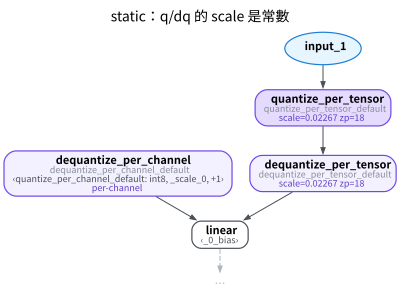

In [10]:
def upto_first_linear(gm):
    """第一個 linear 與它所有的上游 node。"""
    linear = next(n for n in gm.graph.nodes if short(n.target) == "linear")
    kept, todo = set(), [linear]
    while todo:
        n = todo.pop()
        if n.name not in kept:
            kept.add(n.name)
            todo.extend(n.all_input_nodes)
    return kept


draw(converted["static（預設）"], focus=upto_first_linear(converted["static（預設）"]), hops=0,
     title="static：q/dq 的 scale 是常數")

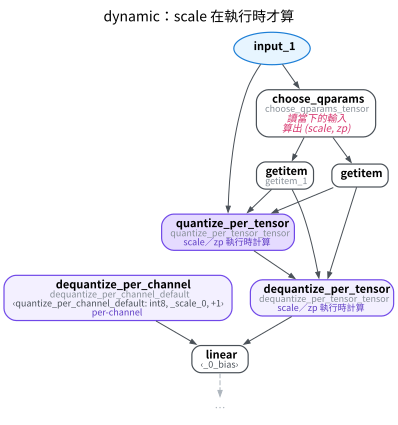

In [11]:
dyn = converted["dynamic"]
choose = next(n.name for n in dyn.graph.nodes if short(n.target) == "choose_qparams")
draw(dyn, focus=upto_first_linear(dyn), hops=0, notes={choose: "讀當下的輸入\n算出 (scale, zp)"},
     title="dynamic：scale 在執行時才算")

In [12]:
n_choose = sum(short(n.target) == "choose_qparams" for n in converted["dynamic"].graph.nodes)
n_linear = sum(short(n.target) == "linear" for n in converted["dynamic"].graph.nodes)
print(f"dynamic 的 choose_qparams：{n_choose} 個；linear：{n_linear} 個")
assert n_choose == n_linear

dynamic 的 choose_qparams：2 個；linear：2 個


- dynamic 在每個 linear 的輸入前插一顆 `choose_qparams`，兩個 `getitem` 取出 scale 與 zero point，交給後面的 quantize、dequantize。
- static 的最後一個 linear 之後還有一對 q/dq（輸出量化）；dynamic 的 output activation 是 `None`，所以沒有。

## C. `set_module_name` 對 conv 生不生效

M03-7 B 發現：torchao 測試版的 `set_module_name("stem", cfg)` 對 conv 默默不生效。executorch 版也一樣嗎？對 TinyConvNet 的 `stem`（conv）與 `fc`（linear）各設一次，其他部分不量化：

In [13]:
tiny = TinyConvNet().eval()
rows, hit = [], {}
for label, source in SOURCES.items():
    cls, cfg_fn, _ = get_xnnpack_api(source)
    for module in ["stem", "fc"]:
        gm = export_module(tiny, example_inputs())
        cls().set_module_name(module, cfg_fn(is_per_channel=True)).annotate(gm)
        names = [n.name for n in gm.graph.nodes if n.op == "call_function" and ANNOTATION_KEY in n.meta]
        hit[(label, module)] = bool(names)
        rows.append([label, module, ", ".join(names) or "（沒有任何標籤）"])
table(rows, ["quantizer", "set_module_name", "有標籤的 node"])

quantizer,set_module_name,有標籤的 node
executorch 版,stem,（沒有任何標籤）
executorch 版,fc,linear
torchao 測試版,stem,（沒有任何標籤）
torchao 測試版,fc,linear


In [14]:
assert all(not hit[(label, "stem")] and hit[(label, "fc")] for label in SOURCES)

兩份一樣：`stem` 的 conv 一個標籤都沒有，`fc` 的 linear 有，而且都不報錯。原因在 module 名稱的篩選，不在 conv 的 annotator：conv 的 pattern 把 weight 的 `get_attr` 也算進去，而 `get_attr` 沒有 `nn_module_stack`，篩選就把整段 conv 跳過（M03-7 B 有完整的追查）。要只量化某一段 conv，自己寫 Quantizer（M03-6）。

## 小結

- 兩份 `XNNPACKQuantizer` 的規格相同：activation int8 per-tensor affine、weight int8 per-channel symmetric、bias 不量化。
- 差在 annotator 的實作：torchao 測試版的 cat 靠 `source_fn_stack` 找 pattern，在 torch 2.14 失效；接在 cat 後面、靠 `propagate_annotation` 的 max_pool2d 跟著沒標。
- `set_module_name` 對 conv 默默不生效，兩份都一樣。
- 換了 quantizer 或版本，就重新檢查標籤（M03-2）。M08 接下來一律用 executorch 版：它和 `XnnpackPartitioner` 在同一個套件，匯出 `.pte` 的流程用的就是這份。